Step 1: Loading the BUSI manifest

In [18]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/Ultrasound_Project-Siyona")
MANIFEST_PATH = PROJECT_ROOT / "data/busi_manifest.csv"

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST_PATH}")

manifest_df = pd.read_csv(MANIFEST_PATH)

print("Manifest path:", MANIFEST_PATH)
print("Number of rows:", len(manifest_df))
print("Columns:", manifest_df.columns.tolist())
print("\nMissing values by column:")
print(manifest_df.isna().sum())

display(manifest_df.head(10))

Manifest path: /content/drive/MyDrive/Ultrasound_Project-Siyona/data/busi_manifest.csv
Number of rows: 780
Columns: ['image_id', 'true_label', 'image_path', 'number_of_masks', 'mask_paths']

Missing values by column:
image_id           0
true_label         0
image_path         0
number_of_masks    0
mask_paths         0
dtype: int64


,image_id,true_label,image_path,number_of_masks,mask_paths
0,benign (1).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
1,benign (10).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
2,benign (100).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,2,/content/drive/MyDrive/Ultrasound_Project-Siyo...
3,benign (101).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
4,benign (102).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
5,benign (103).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
6,benign (104).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
7,benign (105).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
8,benign (106).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...
9,benign (107).png,benign,/content/drive/MyDrive/Ultrasound_Project-Siyo...,1,/content/drive/MyDrive/Ultrasound_Project-Siyo...


In [19]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Step 2: Inspecting single and multiple mask paths

This cell determines the delimiter used by mask_paths and checks whether the number of parsed paths agrees with number_of_masks. It does not open or modify any images.

What are masks?

Masks are annotation images that show where a lesion is located.

A BUSI mask usually has:

- Black pixels for the background.
- White pixels for the annotated lesion.
- The same width and height as its ultrasound image.

For example, the ultrasound image contains the breast tissue and lesion, while its mask acts like a stencil:

```text
Ultrasound image       Segmentation mask
Entire scan            Black background
Visible lesion   →      White lesion region
```

The mask will be converted into a bounding box by finding the smallest rectangle that contains all white lesion pixels:

```text
[x_min, y_min, x_max, y_max]
```

Some ultrasound images have multiple mask files. These may represent multiple annotated regions. The next inspection steps will confirm their contents before deciding how to combine them.

The output confirms that mask_paths uses semicolons and that the parsed path counts match the recorded counts. Most images have one mask; 17 have multiple masks.

In [20]:
single_mask_example = manifest_df.loc[
    manifest_df["number_of_masks"] == 1
].iloc[0]

multiple_mask_examples = manifest_df.loc[
    manifest_df["number_of_masks"] > 1
].head(10)

print("Mask-count distribution:")
print(manifest_df["number_of_masks"].value_counts().sort_index())

print("\nSingle-mask example:")
print("Image ID:", single_mask_example["image_id"])
print("Stored mask_paths:", repr(single_mask_example["mask_paths"]))
print("Parsed paths:", single_mask_example["mask_paths"].split(";"))

print("\nMultiple-mask examples:")
for _, row in multiple_mask_examples.iterrows():
    parsed_paths = row["mask_paths"].split(";")

    print(f"\nImage ID: {row['image_id']}")
    print(f"Recorded number_of_masks: {row['number_of_masks']}")
    print(f"Stored mask_paths: {row['mask_paths']!r}")
    print(f"Parsed path count: {len(parsed_paths)}")

    for path_number, mask_path in enumerate(parsed_paths, start=1):
        print(f"  Mask {path_number}: {mask_path}")

Mask-count distribution:
number_of_masks
1    763
2     16
3      1
Name: count, dtype: int64

Single-mask example:
Image ID: benign (1).png
Stored mask_paths: '/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/BUSI/extracted/Dataset_BUSI_with_GT/benign/benign (1)_mask.png'
Parsed paths: ['/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/BUSI/extracted/Dataset_BUSI_with_GT/benign/benign (1)_mask.png']

Multiple-mask examples:

Image ID: benign (100).png
Recorded number_of_masks: 2
Stored mask_paths: '/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/BUSI/extracted/Dataset_BUSI_with_GT/benign/benign (100)_mask.png;/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/BUSI/extracted/Dataset_BUSI_with_GT/benign/benign (100)_mask_1.png'
Parsed path count: 2
  Mask 1: /content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/BUSI/extracted/Dataset_BUSI_with_GT/benign/benign (100)_mask.png
  Mask 2: /content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/BUSI/e

Step 3: Visualizing multiple masks and their union

This cell opens the image with the greatest number of masks and combines its masks using a logical OR operation. The union preserves every annotated lesion region and will later allow one enclosing ground-truth box to be calculated.

The visualization confirms that the three masks represent three distinct annotated regions. For a single-box grounding task, the masks should be combined by union and one enclosing box should cover all annotated regions.

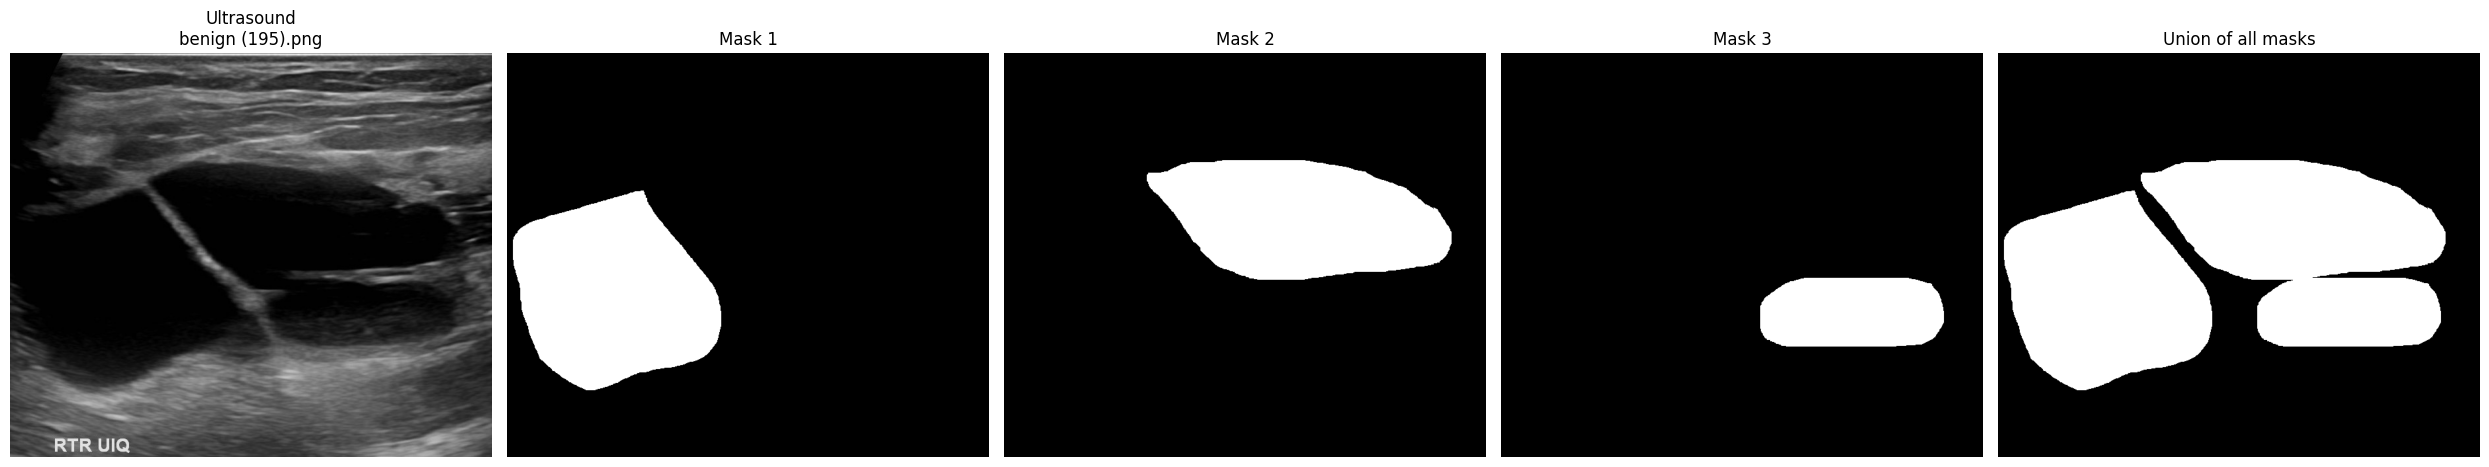

Image size: (611, 729, 3)
Individual mask sizes: [(611, 729), (611, 729), (611, 729)]
Combined foreground pixels: 156339


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

example_row = manifest_df.loc[
    manifest_df["number_of_masks"] == manifest_df["number_of_masks"].max()
].iloc[0]

image = np.array(Image.open(example_row["image_path"]).convert("RGB"))
mask_paths = example_row["mask_paths"].split(";")

binary_masks = []
for mask_path in mask_paths:
    mask = np.array(Image.open(mask_path).convert("L"))
    binary_masks.append(mask > 0)

combined_mask = np.logical_or.reduce(binary_masks)

figure, axes = plt.subplots(
    1,
    len(binary_masks) + 2,
    figsize=(5 * (len(binary_masks) + 2), 5)
)

axes[0].imshow(image)
axes[0].set_title(f"Ultrasound\n{example_row['image_id']}")
axes[0].axis("off")

for mask_index, binary_mask in enumerate(binary_masks, start=1):
    axes[mask_index].imshow(binary_mask, cmap="gray")
    axes[mask_index].set_title(f"Mask {mask_index}")
    axes[mask_index].axis("off")

axes[-1].imshow(combined_mask, cmap="gray")
axes[-1].set_title("Union of all masks")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

print("Image size:", image.shape)
print("Individual mask sizes:", [mask.shape for mask in binary_masks])
print("Combined foreground pixels:", int(combined_mask.sum()))

Step 4: Converting the combined mask into a bounding box

The maximum coordinates are exclusive, meaning they sit one pixel beyond the final foreground pixel. This convention makes box dimensions and later IoU calculations unambiguous.

The box uses four numbers:

```text
[x_min, y_min, x_max, y_max]
```

- `x_min, y_min` marks the first pixel inside the box.
- `x_max, y_max` marks the first pixel immediately outside the box.

For example, if a lesion occupies pixels `10` through `19`, the coordinates are stored as:

```text
x_min = 10
x_max = 20
```

The width is therefore easy to calculate:

```python
width = x_max - x_min  # 20 - 10 = 10 pixels
```

In simple terms, the box begins on the lesion’s first pixel and ends just after its last pixel. Annotation 1

To note: This is not hardcoded.

The values `[9, 162, 677, 510]` were calculated automatically from the white pixels in the mask files:

```python
x_min = int(x_coordinates.min())
y_min = int(y_coordinates.min())
x_max = int(x_coordinates.max()) + 1
y_max = int(y_coordinates.max()) + 1
```

The code also selected this example dynamically because it has the highest `number_of_masks`:

```python
manifest_df["number_of_masks"].max()
```

For every future image, the function will calculate a different box from that image’s actual mask or masks. Only the coordinate format and calculation method are fixed.

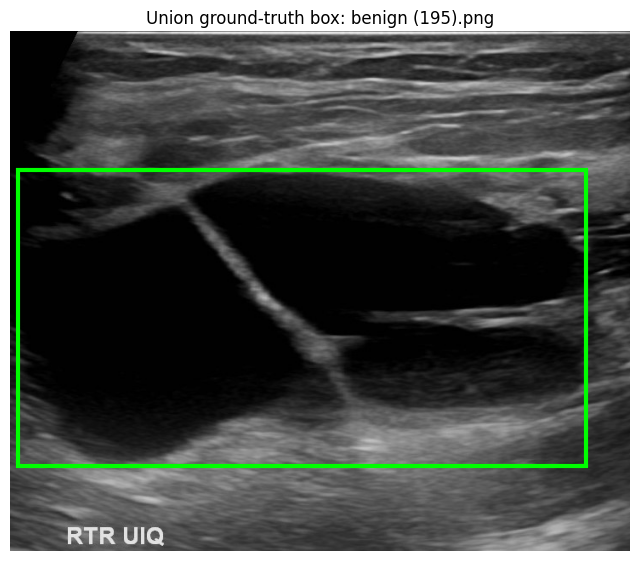

Ground-truth box [x_min, y_min, x_max, y_max]: [9, 162, 677, 510]
Box width: 668
Box height: 348


In [22]:
from matplotlib.patches import Rectangle

def masks_to_union_box(mask_paths):
    """
    Combines all masks for one image and returns one enclosing box.

    Coordinate convention:
    x_min and y_min are inclusive.
    x_max and y_max are exclusive.
    """
    binary_masks = []

    for mask_path in mask_paths:
        mask = np.array(Image.open(mask_path).convert("L"))
        binary_masks.append(mask > 0)

    mask_shapes = {mask.shape for mask in binary_masks}
    if len(mask_shapes) != 1:
        raise ValueError(f"Mask dimensions do not match: {mask_shapes}")

    combined_mask = np.logical_or.reduce(binary_masks)
    y_coordinates, x_coordinates = np.where(combined_mask)

    if len(x_coordinates) == 0:
        return None, combined_mask

    x_min = int(x_coordinates.min())
    y_min = int(y_coordinates.min())
    x_max = int(x_coordinates.max()) + 1
    y_max = int(y_coordinates.max()) + 1

    return [x_min, y_min, x_max, y_max], combined_mask


example_mask_paths = example_row["mask_paths"].split(";")
ground_truth_box, combined_mask = masks_to_union_box(example_mask_paths)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(image)

x_min, y_min, x_max, y_max = ground_truth_box
box_width = x_max - x_min
box_height = y_max - y_min

rectangle = Rectangle(
    (x_min, y_min),
    box_width,
    box_height,
    linewidth=3,
    edgecolor="lime",
    facecolor="none"
)

ax.add_patch(rectangle)
ax.set_title(f"Union ground-truth box: {example_row['image_id']}")
ax.axis("off")
plt.show()

print("Ground-truth box [x_min, y_min, x_max, y_max]:", ground_truth_box)
print("Box width:", box_width)
print("Box height:", box_height)

Step 5: Loading and verifying the fixed BUSI splits

This cell confirms that the development and test sets are separate and together cover the manifest. No images, masks, or model inference are loaded.

In [23]:
DEVELOPMENT_SPLIT_PATH = (
    PROJECT_ROOT / "data/splits/busi_development_20.csv"
)
TEST_SPLIT_PATH = (
    PROJECT_ROOT / "data/splits/busi_test_760.csv"
)

development_df = pd.read_csv(DEVELOPMENT_SPLIT_PATH)
test_df = pd.read_csv(TEST_SPLIT_PATH)

development_ids = set(development_df["image_id"])
test_ids = set(test_df["image_id"])
manifest_ids = set(manifest_df["image_id"])

overlapping_ids = development_ids.intersection(test_ids)
split_ids = development_ids.union(test_ids)

print("Development images:", len(development_df))
print("Test images:", len(test_df))
print("Overlapping image IDs:", len(overlapping_ids))
print("Split images missing from manifest:", len(split_ids - manifest_ids))
print("Manifest images missing from splits:", len(manifest_ids - split_ids))

print("\nDevelopment class distribution:")
print(development_df["true_label"].value_counts())

print("\nTest class distribution:")
print(test_df["true_label"].value_counts())

assert not overlapping_ids, "Development and test splits overlap"
assert split_ids == manifest_ids, "The splits do not exactly cover the manifest"

print("\nSplit verification passed.")

Development images: 20
Test images: 760
Overlapping image IDs: 0
Split images missing from manifest: 0
Manifest images missing from splits: 0

Development class distribution:
true_label
benign       11
malignant     5
normal        4
Name: count, dtype: int64

Test class distribution:
true_label
benign       426
malignant    205
normal       129
Name: count, dtype: int64

Split verification passed.


Step 6: Validating boxes on the development set only

This cell opens and validates only the 20 development images. The 760 test images remain untouched.

In [24]:
development_manifest_df = (
    development_df[["image_id"]]
    .merge(
        manifest_df,
        on="image_id",
        how="left",
        validate="one_to_one"
    )
)

development_validation_records = []

for _, row in development_manifest_df.iterrows():
    image_array = np.array(Image.open(row["image_path"]).convert("RGB"))
    image_height, image_width = image_array.shape[:2]

    mask_paths = row["mask_paths"].split(";")
    ground_truth_box, combined_mask = masks_to_union_box(mask_paths)

    box_is_valid = False
    issue = ""

    if combined_mask.shape != (image_height, image_width):
        issue = "Image and mask dimensions do not match"
    elif ground_truth_box is None:
        issue = "Mask contains no foreground pixels"
    else:
        x_min, y_min, x_max, y_max = ground_truth_box

        box_is_valid = (
            0 <= x_min < x_max <= image_width
            and 0 <= y_min < y_max <= image_height
        )

        if not box_is_valid:
            issue = "Bounding box is outside the image"

    development_validation_records.append({
        "image_id": row["image_id"],
        "true_label": row["true_label"],
        "image_width": image_width,
        "image_height": image_height,
        "number_of_masks": row["number_of_masks"],
        "ground_truth_box": ground_truth_box,
        "box_is_valid": box_is_valid,
        "issue": issue
    })

development_box_df = pd.DataFrame(development_validation_records)

print("Development images checked:", len(development_box_df))
print("Valid boxes:", int(development_box_df["box_is_valid"].sum()))
print("Invalid boxes:", int((~development_box_df["box_is_valid"]).sum()))

display(development_box_df)

Development images checked: 20
Valid boxes: 16
Invalid boxes: 4


,image_id,true_label,image_width,image_height,number_of_masks,ground_truth_box,box_is_valid,issue
0,benign (191).png,benign,549,463,1,"[200, 102, 312, 144]",True,
1,benign (117).png,benign,806,688,1,"[587, 124, 733, 252]",True,
2,benign (195).png,benign,729,611,3,"[9, 162, 677, 510]",True,
3,benign (98).png,benign,795,558,2,"[0, 88, 695, 419]",True,
4,benign (99).png,benign,554,471,1,"[300, 56, 447, 151]",True,
5,benign (412).png,benign,779,576,1,"[75, 53, 692, 465]",True,
6,normal (84).png,normal,509,477,1,None,False,Mask contains no foreground pixels
7,malignant (160).png,malignant,626,587,1,"[192, 152, 613, 436]",True,
8,normal (22).png,normal,552,470,1,None,False,Mask contains no foreground pixels
9,benign (208).png,benign,562,479,1,"[196, 110, 273, 163]",True,


Step 7: Separating lesion images from no-lesion images

This cell corrects the interpretation of the earlier table. Lesion images with valid boxes are eligible for IoU, while normal images correctly have no target box.

In [25]:
development_grounding_df = development_box_df.copy()

development_grounding_df["has_lesion_target"] = (
    development_grounding_df["true_label"].isin(["benign", "malignant"])
)

development_grounding_df["grounding_status"] = np.where(
    development_grounding_df["has_lesion_target"]
    & development_grounding_df["box_is_valid"],
    "eligible for IoU",
    np.where(
        ~development_grounding_df["has_lesion_target"]
        & development_grounding_df["ground_truth_box"].isna(),
        "normal image: no target box",
        "annotation problem"
    )
)

print("Grounding status counts:")
print(development_grounding_df["grounding_status"].value_counts())

print("\nStatus by true class:")
display(
    pd.crosstab(
        development_grounding_df["true_label"],
        development_grounding_df["grounding_status"]
    )
)

annotation_problems = development_grounding_df.loc[
    development_grounding_df["grounding_status"] == "annotation problem"
]

assert annotation_problems.empty, (
    "At least one development image has an unexpected annotation problem."
)

print("\nDevelopment grounding annotations are consistent.")

Grounding status counts:
grounding_status
eligible for IoU               16
normal image: no target box     4
Name: count, dtype: int64

Status by true class:


grounding_status,eligible for IoU,normal image: no target box
true_label,,
benign,11,0
malignant,5,0
normal,0,4



Development grounding annotations are consistent.


Step 8: Defining the grounding prompt and output schema

Normalized coordinates allow the same 0–1000 scale to work with every image size. For example, x = 500 means halfway across the image, regardless of its pixel width.
The schema also supports normal images by returning box: null. No inference is run in this step.

In [26]:
GROUNDING_PROMPT = """Locate the breast lesion or lesions in this ultrasound image.

Return JSON only using exactly one of these formats:

If one or more lesions are visible:
{"lesion_present": true, "box": [x_min, y_min, x_max, y_max]}

If no lesion is visible:
{"lesion_present": false, "box": null}

Use one box that encloses all visible lesions.

Coordinates must be integers normalized from 0 to 1000:
- x_min: left edge
- y_min: top edge
- x_max: right edge
- y_max: bottom edge

The top-left corner of the image is [0, 0].
The bottom-right corner is [1000, 1000].
Return no explanation outside the JSON.
"""

GROUNDING_PROMPT_PATH = (
    PROJECT_ROOT / "prompts/busi_grounding_v1.txt"
)

GROUNDING_PROMPT_PATH.parent.mkdir(parents=True, exist_ok=True)
GROUNDING_PROMPT_PATH.write_text(GROUNDING_PROMPT, encoding="utf-8")

print(GROUNDING_PROMPT)
print("Prompt saved to:", GROUNDING_PROMPT_PATH)

Locate the breast lesion or lesions in this ultrasound image.

Return JSON only using exactly one of these formats:

If one or more lesions are visible:
{"lesion_present": true, "box": [x_min, y_min, x_max, y_max]}

If no lesion is visible:
{"lesion_present": false, "box": null}

Use one box that encloses all visible lesions.

Coordinates must be integers normalized from 0 to 1000:
- x_min: left edge
- y_min: top edge
- x_max: right edge
- y_max: bottom edge

The top-left corner of the image is [0, 0].
The bottom-right corner is [1000, 1000].
Return no explanation outside the JSON.

Prompt saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/prompts/busi_grounding_v1.txt


Step 9: Converting between pixels and the 0–1000 scale

This cell creates two translators:
- The first changes the real pixel box into the model’s 0–1000 scale.
- The second changes the model’s answer back into real pixels.
“Normalized” simply means changing different image sizes to the same common scale. Small differences of about one pixel after converting back are normal because coordinates are rounded to whole numbers.

In [27]:
def pixel_box_to_normalized(box, image_width, image_height):
    x_min, y_min, x_max, y_max = box

    return [
        round(x_min / image_width * 1000),
        round(y_min / image_height * 1000),
        round(x_max / image_width * 1000),
        round(y_max / image_height * 1000)
    ]


def normalized_box_to_pixels(box, image_width, image_height):
    x_min, y_min, x_max, y_max = box

    pixel_box = [
        round(x_min / 1000 * image_width),
        round(y_min / 1000 * image_height),
        round(x_max / 1000 * image_width),
        round(y_max / 1000 * image_height)
    ]

    pixel_box[0] = max(0, min(pixel_box[0], image_width))
    pixel_box[1] = max(0, min(pixel_box[1], image_height))
    pixel_box[2] = max(0, min(pixel_box[2], image_width))
    pixel_box[3] = max(0, min(pixel_box[3], image_height))

    return pixel_box


example_record = development_grounding_df.loc[
    development_grounding_df["grounding_status"] == "eligible for IoU"
].iloc[0]

original_pixel_box = example_record["ground_truth_box"]

normalized_box = pixel_box_to_normalized(
    original_pixel_box,
    example_record["image_width"],
    example_record["image_height"]
)

converted_back_box = normalized_box_to_pixels(
    normalized_box,
    example_record["image_width"],
    example_record["image_height"]
)

print("Image ID:", example_record["image_id"])
print("Image size:", example_record["image_width"], "x", example_record["image_height"])
print("Original pixel box:", original_pixel_box)
print("Normalized box:", normalized_box)
print("Converted back to pixels:", converted_back_box)

Image ID: benign (191).png
Image size: 549 x 463
Original pixel box: [200, 102, 312, 144]
Normalized box: [364, 220, 568, 311]
Converted back to pixels: [200, 102, 312, 144]


Step 10: Creating the IoU calculation

IoU means “intersection over union.” In simple terms, it measures how closely the model’s rectangle matches the correct rectangle:
- 1.0 means the boxes match perfectly.
- 0.0 means they do not overlap.
- A value between 0 and 1 means they overlap partly.
This cell tests the calculation using one perfect match and one box placed elsewhere. It does not run the model.

In [28]:
def calculate_iou(box_a, box_b):
    """
    Calculates how much two boxes overlap.

    Returns:
        A value from 0 to 1.
        0 means no overlap.
        1 means a perfect match.
    """
    if box_a is None or box_b is None:
        return np.nan

    a_x_min, a_y_min, a_x_max, a_y_max = box_a
    b_x_min, b_y_min, b_x_max, b_y_max = box_b

    overlap_x_min = max(a_x_min, b_x_min)
    overlap_y_min = max(a_y_min, b_y_min)
    overlap_x_max = min(a_x_max, b_x_max)
    overlap_y_max = min(a_y_max, b_y_max)

    overlap_width = max(0, overlap_x_max - overlap_x_min)
    overlap_height = max(0, overlap_y_max - overlap_y_min)
    overlap_area = overlap_width * overlap_height

    area_a = (a_x_max - a_x_min) * (a_y_max - a_y_min)
    area_b = (b_x_max - b_x_min) * (b_y_max - b_y_min)

    combined_area = area_a + area_b - overlap_area

    if combined_area <= 0:
        return np.nan

    return overlap_area / combined_area


example_box = original_pixel_box

identical_box = example_box.copy()

non_overlapping_box = [
    example_record["image_width"] - 10,
    example_record["image_height"] - 10,
    example_record["image_width"],
    example_record["image_height"]
]

print(
    "IoU for identical boxes:",
    calculate_iou(example_box, identical_box)
)

print(
    "IoU for non-overlapping boxes:",
    calculate_iou(example_box, non_overlapping_box)
)

IoU for identical boxes: 1.0
IoU for non-overlapping boxes: 0.0


Step 11: Checking whether a model answer follows the required format

A parser is code that reads the model’s text and turns it into values the notebook can use. This parser also checks that:
- The answer is valid JSON.
- All required parts are present.
- The coordinates are whole numbers between 0 and 1000.
- The left edge comes before the right edge.
- The top edge comes before the bottom edge.
The two strings at the bottom are only format tests, not model predictions or evaluation results.

In [29]:
import json

def parse_grounding_response(response_text):
    """
    Reads and checks a MedGemma grounding response.
    """
    try:
        parsed = json.loads(response_text.strip())
    except json.JSONDecodeError:
        return {
            "valid": False,
            "lesion_present": None,
            "normalized_box": None,
            "error": "Response is not valid JSON"
        }

    if set(parsed.keys()) != {"lesion_present", "box"}:
        return {
            "valid": False,
            "lesion_present": None,
            "normalized_box": None,
            "error": "Response has unexpected or missing fields"
        }

    lesion_present = parsed["lesion_present"]
    box = parsed["box"]

    if not isinstance(lesion_present, bool):
        return {
            "valid": False,
            "lesion_present": None,
            "normalized_box": None,
            "error": "lesion_present must be true or false"
        }

    if lesion_present is False:
        if box is not None:
            return {
                "valid": False,
                "lesion_present": False,
                "normalized_box": None,
                "error": "box must be null when no lesion is present"
            }

        return {
            "valid": True,
            "lesion_present": False,
            "normalized_box": None,
            "error": ""
        }

    if (
        not isinstance(box, list)
        or len(box) != 4
        or any(isinstance(value, bool) or not isinstance(value, int) for value in box)
    ):
        return {
            "valid": False,
            "lesion_present": True,
            "normalized_box": None,
            "error": "box must contain four integers"
        }

    x_min, y_min, x_max, y_max = box

    if not all(0 <= value <= 1000 for value in box):
        return {
            "valid": False,
            "lesion_present": True,
            "normalized_box": None,
            "error": "box coordinates must be between 0 and 1000"
        }

    if x_min >= x_max or y_min >= y_max:
        return {
            "valid": False,
            "lesion_present": True,
            "normalized_box": None,
            "error": "box edges are in the wrong order"
        }

    return {
        "valid": True,
        "lesion_present": True,
        "normalized_box": box,
        "error": ""
    }


lesion_example = (
    '{"lesion_present": true, "box": [200, 150, 700, 650]}'
)

no_lesion_example = (
    '{"lesion_present": false, "box": null}'
)

print("Lesion example:")
print(parse_grounding_response(lesion_example))

print("\nNo-lesion example:")
print(parse_grounding_response(no_lesion_example))

Lesion example:
{'valid': True, 'lesion_present': True, 'normalized_box': [200, 150, 700, 650], 'error': ''}

No-lesion example:
{'valid': True, 'lesion_present': False, 'normalized_box': None, 'error': ''}


Step 12: Checking the Colab hardware

In [30]:
import torch
import transformers

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Do not load MedGemma yet.")

PyTorch version: 2.11.0+cu130
Transformers version: 5.22.0
GPU available: True
GPU name: Tesla T4


Step 13: Checking Hugging Face access

In [31]:
from huggingface_hub import whoami

try:
    account_info = whoami()
    print("Signed in to Hugging Face as:", account_info["name"])
    print("Hugging Face access is ready.")
except Exception as error:
    print("Hugging Face is not signed in.")
    print("Error:", error)

Signed in to Hugging Face as: siyonanaik
Hugging Face access is ready.


Step 14: Loading MedGemma

In [17]:
from transformers import (
    AutoProcessor,
    AutoModelForImageTextToText,
    BitsAndBytesConfig
)

MODEL_ID = "google/medgemma-1.5-4b-it"
MODEL_REVISION = "91850547d9f0b2fdd21aa7c5f4f3d1a8a52c243b"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION
)

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    quantization_config=quantization_config,
    device_map="auto"
)

model.eval()

print("Model loaded:", MODEL_ID)
print("Revision:", MODEL_REVISION)
print("Model device:", model.device)

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Model loaded: google/medgemma-1.5-4b-it
Revision: 91850547d9f0b2fdd21aa7c5f4f3d1a8a52c243b
Model device: cuda:0


In [6]:
!pip install -q bitsandbytes==0.50.2

Step 15: Checking that everything is ready

This simply checks whether the important variables and functions exist in memory. It does not run MedGemma or open any test images.

In [ ]:
required_items = [
    "development_manifest_df",
    "development_grounding_df",
    "GROUNDING_PROMPT",
    "pixel_box_to_normalized",
    "normalized_box_to_pixels",
    "calculate_iou",
    "parse_grounding_response",
    "processor",
    "model"
]

missing_items = [
    item for item in required_items
    if item not in globals()
]

if missing_items:
    print("Missing items:", missing_items)
else:
    print("Everything is ready for the one-image test.")

print(
    "Model loaded on GPU:",
    "model" in globals() and str(model.device).startswith("cuda")
)

Everything is ready for the one-image test.
Model loaded on GPU: True


Step 16: Running MedGemma on one development image



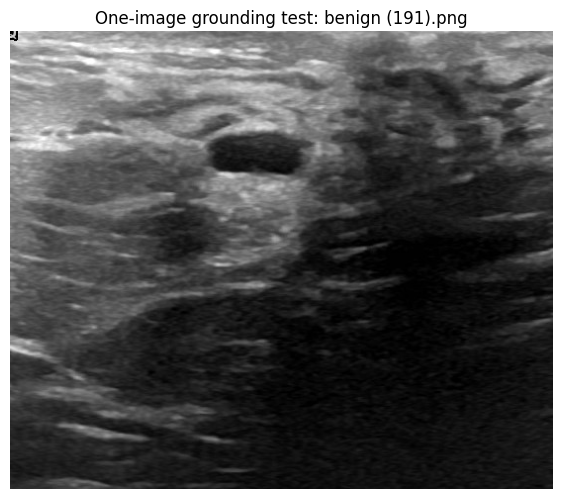

Image ID: benign (191).png
True label: benign
Raw MedGemma response: ```json
{"lesion_present": true, "box": [100, 100, 500, 500]}
```
Parsed response: {'valid': False, 'lesion_present': None, 'normalized_box': None, 'error': 'Response is not valid JSON'}
Time taken: 6.98 seconds


In [ ]:
import time

one_image_record = development_grounding_df.loc[
    development_grounding_df["grounding_status"] == "eligible for IoU"
].iloc[0]

one_image_id = one_image_record["image_id"]

one_image_manifest_row = development_manifest_df.loc[
    development_manifest_df["image_id"] == one_image_id
].iloc[0]

one_image = Image.open(
    one_image_manifest_row["image_path"]
).convert("RGB")

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": one_image},
            {"type": "text", "text": GROUNDING_PROMPT}
        ]
    }
]

model_inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
)

model_inputs = {
    name: value.to(model.device)
    for name, value in model_inputs.items()
}

input_token_count = model_inputs["input_ids"].shape[-1]

start_time = time.time()

with torch.inference_mode():
    generated_tokens = model.generate(
        **model_inputs,
        max_new_tokens=100,
        do_sample=False
    )

latency_seconds = time.time() - start_time

new_tokens = generated_tokens[0][input_token_count:]

raw_response = processor.decode(
    new_tokens,
    skip_special_tokens=True
).strip()

parsed_response = parse_grounding_response(raw_response)

plt.figure(figsize=(7, 6))
plt.imshow(one_image)
plt.title(f"One-image grounding test: {one_image_id}")
plt.axis("off")
plt.show()

print("Image ID:", one_image_id)
print("True label:", one_image_record["true_label"])
print("Raw MedGemma response:", raw_response)
print("Parsed response:", parsed_response)
print("Time taken:", round(latency_seconds, 2), "seconds")

Step 17: Fixing the model response

This removes the extra backticks added by MedGemma and reads the JSON again. It does not rerun the model.

In [ ]:
cleaned_response = (
    raw_response
    .replace("```json", "")
    .replace("```", "")
    .strip()
)

parsed_response = parse_grounding_response(cleaned_response)

print("Cleaned response:", cleaned_response)
print("Parsed response:", parsed_response)

Cleaned response: {"lesion_present": true, "box": [100, 100, 500, 500]}
Parsed response: {'valid': True, 'lesion_present': True, 'normalized_box': [100, 100, 500, 500], 'error': ''}


Step 18: Comparing the predicted box with the correct box

The green rectangle is the correct box from the mask. The red rectangle is MedGemma’s prediction. IoU measures how closely they overlap.

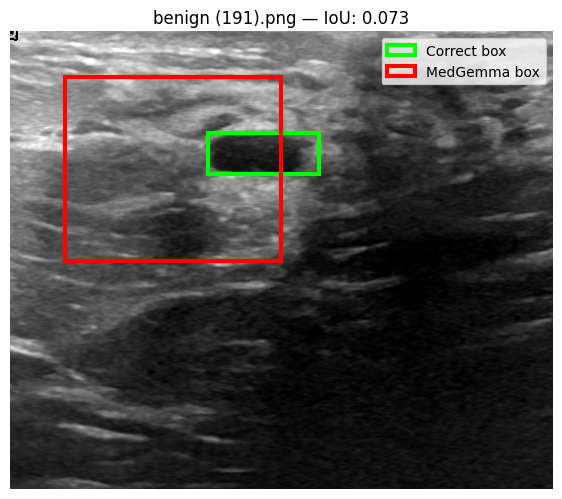

Correct box: [200, 102, 312, 144]
MedGemma box: [55, 46, 274, 232]
IoU: 0.0734


In [ ]:
image_width, image_height = one_image.size

predicted_pixel_box = normalized_box_to_pixels(
    parsed_response["normalized_box"],
    image_width,
    image_height
)

correct_pixel_box = one_image_record["ground_truth_box"]

one_image_iou = calculate_iou(
    correct_pixel_box,
    predicted_pixel_box
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(one_image)

correct_x1, correct_y1, correct_x2, correct_y2 = correct_pixel_box
predicted_x1, predicted_y1, predicted_x2, predicted_y2 = predicted_pixel_box

ax.add_patch(Rectangle(
    (correct_x1, correct_y1),
    correct_x2 - correct_x1,
    correct_y2 - correct_y1,
    edgecolor="lime",
    facecolor="none",
    linewidth=3,
    label="Correct box"
))

ax.add_patch(Rectangle(
    (predicted_x1, predicted_y1),
    predicted_x2 - predicted_x1,
    predicted_y2 - predicted_y1,
    edgecolor="red",
    facecolor="none",
    linewidth=3,
    label="MedGemma box"
))

ax.set_title(f"{one_image_id} — IoU: {one_image_iou:.3f}")
ax.legend()
ax.axis("off")
plt.show()

print("Correct box:", correct_pixel_box)
print("MedGemma box:", predicted_pixel_box)
print("IoU:", round(one_image_iou, 4))

Step 19: Creating a reusable prediction function

Instead of repeating the inference code for every development image, this function can process one supplied image path and return its prediction.

In [ ]:
def predict_grounding(image_path):
    image = Image.open(image_path).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": GROUNDING_PROMPT}
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        name: value.to(model.device)
        for name, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]
    start_time = time.time()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    latency = time.time() - start_time

    response_text = processor.decode(
        output[0][input_length:],
        skip_special_tokens=True
    ).strip()

    cleaned_text = (
        response_text
        .replace("```json", "")
        .replace("```", "")
        .strip()
    )

    parsed = parse_grounding_response(cleaned_text)

    predicted_pixel_box = None

    if parsed["valid"] and parsed["normalized_box"] is not None:
        predicted_pixel_box = normalized_box_to_pixels(
            parsed["normalized_box"],
            image.width,
            image.height
        )

    return {
        "raw_response": response_text,
        "valid_response": parsed["valid"],
        "predicted_lesion_present": parsed["lesion_present"],
        "predicted_normalized_box": parsed["normalized_box"],
        "predicted_pixel_box": predicted_pixel_box,
        "parse_error": parsed["error"],
        "latency_seconds": latency
    }


print("Prediction function created.")

Prediction function created.


Step 20: Running the 20 development images



In [ ]:
GROUNDING_RESULTS_DIR = (
    PROJECT_ROOT / "results/busi_grounding"
)

GROUNDING_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEVELOPMENT_RESULTS_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_development_grounding_medgemma.csv"
)

development_run_df = development_manifest_df.merge(
    development_grounding_df[
        [
            "image_id",
            "ground_truth_box",
            "grounding_status"
        ]
    ],
    on="image_id",
    how="left",
    validate="one_to_one"
)

results = []

# Reuse the prediction already made for the first image.
results.append({
    "image_id": one_image_id,
    "true_label": one_image_record["true_label"],
    "ground_truth_box": one_image_record["ground_truth_box"],
    "raw_response": raw_response,
    "valid_response": parsed_response["valid"],
    "predicted_lesion_present": parsed_response["lesion_present"],
    "predicted_normalized_box": parsed_response["normalized_box"],
    "predicted_pixel_box": predicted_pixel_box,
    "iou": one_image_iou,
    "latency_seconds": latency_seconds
})

completed_ids = {one_image_id}

for _, row in development_run_df.iterrows():
    if row["image_id"] in completed_ids:
        continue

    prediction = predict_grounding(row["image_path"])

    true_lesion_present = row["true_label"] in [
        "benign",
        "malignant"
    ]

    image_iou = np.nan

    if (
        true_lesion_present
        and prediction["predicted_pixel_box"] is not None
    ):
        image_iou = calculate_iou(
            row["ground_truth_box"],
            prediction["predicted_pixel_box"]
        )

    results.append({
        "image_id": row["image_id"],
        "true_label": row["true_label"],
        "ground_truth_box": row["ground_truth_box"],
        "raw_response": prediction["raw_response"],
        "valid_response": prediction["valid_response"],
        "predicted_lesion_present": (
            prediction["predicted_lesion_present"]
        ),
        "predicted_normalized_box": (
            prediction["predicted_normalized_box"]
        ),
        "predicted_pixel_box": (
            prediction["predicted_pixel_box"]
        ),
        "iou": image_iou,
        "latency_seconds": prediction["latency_seconds"]
    })

    pd.DataFrame(results).to_csv(
        DEVELOPMENT_RESULTS_PATH,
        index=False
    )

    print(
        f"Completed {len(results)} of "
        f"{len(development_run_df)} images"
    )

development_results_df = pd.DataFrame(results)

development_results_df.to_csv(
    DEVELOPMENT_RESULTS_PATH,
    index=False
)

print("\nDevelopment run complete.")
print("Results saved to:", DEVELOPMENT_RESULTS_PATH)
print("Images completed:", len(development_results_df))

Completed 2 of 20 images
Completed 3 of 20 images
Completed 4 of 20 images
Completed 5 of 20 images
Completed 6 of 20 images
Completed 7 of 20 images
Completed 8 of 20 images
Completed 9 of 20 images
Completed 10 of 20 images
Completed 11 of 20 images
Completed 12 of 20 images
Completed 13 of 20 images
Completed 14 of 20 images
Completed 15 of 20 images
Completed 16 of 20 images
Completed 17 of 20 images
Completed 18 of 20 images
Completed 19 of 20 images
Completed 20 of 20 images

Development run complete.
Results saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_development_grounding_medgemma.csv
Images completed: 20


Step 21: Summarizing the development results

This calculates:
- How often MedGemma returned a usable answer.
- How often it correctly decided whether a lesion was present.
- The average and middle IoU for lesion images.
- How often IoU reached 0.25 and 0.50.
- The average time per image.
A missing or unusable box receives an IoU of 0 for a lesion image. Normal images are not included in the IoU calculation because they have no correct box.

In [ ]:
development_results_df["true_lesion_present"] = (
    development_results_df["true_label"]
    .isin(["benign", "malignant"])
)

development_results_df["lesion_presence_correct"] = (
    development_results_df["valid_response"]
    & (
        development_results_df["predicted_lesion_present"]
        == development_results_df["true_lesion_present"]
    )
)

development_results_df["evaluation_iou"] = np.where(
    development_results_df["true_lesion_present"],
    pd.to_numeric(
        development_results_df["iou"],
        errors="coerce"
    ).fillna(0),
    np.nan
)

lesion_results = development_results_df.loc[
    development_results_df["true_lesion_present"]
].copy()

development_summary_df = pd.DataFrame([{
    "total_images": len(development_results_df),
    "valid_response_rate": (
        development_results_df["valid_response"].mean()
    ),
    "lesion_presence_accuracy": (
        development_results_df[
            "lesion_presence_correct"
        ].mean()
    ),
    "mean_iou_lesion_images": (
        lesion_results["evaluation_iou"].mean()
    ),
    "median_iou_lesion_images": (
        lesion_results["evaluation_iou"].median()
    ),
    "iou_at_least_0_25_rate": (
        lesion_results["evaluation_iou"] >= 0.25
    ).mean(),
    "iou_at_least_0_50_rate": (
        lesion_results["evaluation_iou"] >= 0.50
    ).mean(),
    "average_latency_seconds": (
        development_results_df["latency_seconds"].mean()
    )
}])

DEVELOPMENT_SUMMARY_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_development_grounding_summary.csv"
)

development_results_df.to_csv(
    DEVELOPMENT_RESULTS_PATH,
    index=False
)

development_summary_df.to_csv(
    DEVELOPMENT_SUMMARY_PATH,
    index=False
)

display(development_summary_df.T.rename(columns={0: "value"}))

print("Summary saved to:", DEVELOPMENT_SUMMARY_PATH)

,value
total_images,20.000000
valid_response_rate,1.000000
lesion_presence_accuracy,0.800000
mean_iou_lesion_images,0.295814
median_iou_lesion_images,0.271914
iou_at_least_0_25_rate,0.500000
iou_at_least_0_50_rate,0.250000
average_latency_seconds,5.956568


Summary saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_development_grounding_summary.csv


Step 22: Checking where the development errors occurred

This shows whether the model’s lesion-presence errors came from normal images or lesion images. It also lists which lesion boxes matched well or poorly.

The development run shows that MedGemma predicted a lesion in every image, including all four normal images. It also reused several broad, simple boxes. The pipeline works, but the model’s grounding performance is limited.
The prompt and settings should now stay fixed so the test results remain fair.

In [ ]:
print("Lesion-presence predictions by true class:")

display(
    pd.crosstab(
        development_results_df["true_label"],
        development_results_df[
            "predicted_lesion_present"
        ],
        margins=True
    )
)

print("\nNormal-image predictions:")

display(
    development_results_df.loc[
        development_results_df["true_label"] == "normal",
        [
            "image_id",
            "predicted_lesion_present",
            "predicted_normalized_box",
            "raw_response"
        ]
    ]
)

print("\nLesion images ordered from lowest to highest IoU:")

display(
    lesion_results[
        [
            "image_id",
            "true_label",
            "evaluation_iou",
            "predicted_normalized_box"
        ]
    ].sort_values("evaluation_iou")
)

Lesion-presence predictions by true class:


predicted_lesion_present,True,All
true_label,,
benign,11,11
malignant,5,5
normal,4,4
All,20,20



Normal-image predictions:


,image_id,predicted_lesion_present,predicted_normalized_box,raw_response
6,normal (84).png,True,"[100, 100, 800, 800]","```json\n{""lesion_present"": true, ""box"": [100,..."
8,normal (22).png,True,"[100, 100, 800, 800]","```json\n{""lesion_present"": true, ""box"": [100,..."
11,normal (1).png,True,"[100, 100, 800, 800]","```json\n{""lesion_present"": true, ""box"": [100,..."
15,normal (110).png,True,"[100, 100, 800, 800]","```json\n{""lesion_present"": true, ""box"": [100,..."



Lesion images ordered from lowest to highest IoU:


,image_id,true_label,evaluation_iou,predicted_normalized_box
1,benign (117).png,benign,0.000000,"[100, 100, 500, 500]"
4,benign (99).png,benign,0.000000,"[100, 100, 500, 500]"
0,benign (191).png,benign,0.073423,"[100, 100, 500, 500]"
10,benign (292).png,benign,0.088368,"[100, 100, 800, 800]"
16,benign (163).png,benign,0.098163,"[100, 100, 800, 800]"
9,benign (208).png,benign,0.107963,"[100, 150, 500, 500]"
18,benign (269).png,benign,0.108558,"[100, 100, 800, 800]"
12,malignant (81).png,malignant,0.242265,"[100, 100, 800, 800]"
13,malignant (118).png,malignant,0.301563,"[100, 100, 700, 700]"
19,benign (342).png,benign,0.352201,"[100, 100, 800, 800]"


Step 23: Preparing the 760 test annotations

This checks the masks for the 760 test images and creates their correct boxes. It does not run MedGemma.
Normal images should have no box. Benign and malignant images should have a valid box.

In [ ]:
test_manifest_df = (
    test_df[["image_id"]]
    .merge(
        manifest_df,
        on="image_id",
        how="left",
        validate="one_to_one"
    )
)

test_ground_truth_records = []

for completed, (_, row) in enumerate(
    test_manifest_df.iterrows(),
    start=1
):
    image = Image.open(row["image_path"]).convert("RGB")
    image_width, image_height = image.size

    mask_paths = row["mask_paths"].split(";")

    ground_truth_box, combined_mask = masks_to_union_box(
        mask_paths
    )

    has_lesion_target = row["true_label"] in [
        "benign",
        "malignant"
    ]

    if has_lesion_target and ground_truth_box is not None:
        annotation_status = "eligible for IoU"
    elif not has_lesion_target and ground_truth_box is None:
        annotation_status = "normal image: no target box"
    else:
        annotation_status = "annotation problem"

    test_ground_truth_records.append({
        "image_id": row["image_id"],
        "true_label": row["true_label"],
        "image_path": row["image_path"],
        "image_width": image_width,
        "image_height": image_height,
        "ground_truth_box": ground_truth_box,
        "annotation_status": annotation_status
    })

    if completed % 100 == 0:
        print(
            f"Checked {completed} of "
            f"{len(test_manifest_df)} images"
        )

test_ground_truth_df = pd.DataFrame(
    test_ground_truth_records
)

print("\nAnnotation status:")
print(
    test_ground_truth_df[
        "annotation_status"
    ].value_counts()
)

assert not (
    test_ground_truth_df["annotation_status"]
    == "annotation problem"
).any()

print("\nAll test annotations are consistent.")

Checked 100 of 760 images
Checked 200 of 760 images
Checked 300 of 760 images
Checked 400 of 760 images
Checked 500 of 760 images
Checked 600 of 760 images
Checked 700 of 760 images

Annotation status:
annotation_status
eligible for IoU               631
normal image: no target box    129
Name: count, dtype: int64

All test annotations are consistent.


Step 24: Saving the test ground-truth boxes

This saves the correct test boxes before starting the long model run. If Colab disconnects later, these boxes will not need to be created again.

In [27]:
TEST_GROUND_TRUTH_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_test_ground_truth_boxes.csv"
)

test_ground_truth_df.to_csv(
    TEST_GROUND_TRUTH_PATH,
    index=False
)

print("Test annotations saved to:", TEST_GROUND_TRUTH_PATH)
print("Rows saved:", len(test_ground_truth_df))

Test annotations saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_test_ground_truth_boxes.csv
Rows saved: 760


Step 25: Running the full test grounding evaluation

This runs MedGemma on the 760 untouched test images. It saves the CSV after every image.

In [34]:
TEST_RESULTS_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_test_grounding_medgemma.csv"
)

if TEST_RESULTS_PATH.exists():
    test_results_df = pd.read_csv(TEST_RESULTS_PATH)
    results = test_results_df.to_dict("records")
    print("Existing checkpoint loaded.")
else:
    results = []
    print("Starting a new test run.")

completed_ids = {
    record["image_id"]
    for record in results
}

for _, row in test_ground_truth_df.iterrows():
    if row["image_id"] in completed_ids:
        continue

    try:
        prediction = predict_grounding(row["image_path"])

        true_lesion_present = row["true_label"] in [
            "benign",
            "malignant"
        ]

        lesion_presence_correct = (
            prediction["valid_response"]
            and (
                prediction["predicted_lesion_present"]
                == true_lesion_present
            )
        )

        image_iou = np.nan

        if true_lesion_present:
            image_iou = 0.0

            if prediction["predicted_pixel_box"] is not None:
                image_iou = calculate_iou(
                    row["ground_truth_box"],
                    prediction["predicted_pixel_box"]
                )

        results.append({
            "image_id": row["image_id"],
            "true_label": row["true_label"],
            "ground_truth_box": row["ground_truth_box"],
            "raw_response": prediction["raw_response"],
            "valid_response": prediction["valid_response"],
            "predicted_lesion_present": (
                prediction["predicted_lesion_present"]
            ),
            "predicted_normalized_box": (
                prediction["predicted_normalized_box"]
            ),
            "predicted_pixel_box": (
                prediction["predicted_pixel_box"]
            ),
            "lesion_presence_correct": (
                lesion_presence_correct
            ),
            "iou": image_iou,
            "latency_seconds": prediction["latency_seconds"]
        })

        completed_ids.add(row["image_id"])

        test_results_df = pd.DataFrame(results)

        test_results_df.to_csv(
            TEST_RESULTS_PATH,
            index=False
        )

        if len(results) % 10 == 0:
            print(
                f"Completed {len(results)} of "
                f"{len(test_ground_truth_df)} images"
            )

    except Exception as error:
        print("Run stopped at:", row["image_id"])
        print("Error:", error)
        break

test_results_df = pd.DataFrame(results)

print("\nCompleted images:", len(test_results_df))
print(
    "Remaining images:",
    len(test_ground_truth_df) - len(test_results_df)
)
print("Checkpoint:", TEST_RESULTS_PATH)

Existing checkpoint loaded.
Completed 580 of 760 images
Completed 590 of 760 images
Completed 600 of 760 images
Completed 610 of 760 images
Completed 620 of 760 images
Completed 630 of 760 images
Completed 640 of 760 images
Completed 650 of 760 images
Completed 660 of 760 images
Completed 670 of 760 images
Completed 680 of 760 images
Completed 690 of 760 images
Completed 700 of 760 images
Completed 710 of 760 images
Completed 720 of 760 images
Completed 730 of 760 images
Completed 740 of 760 images
Completed 750 of 760 images
Completed 760 of 760 images

Completed images: 760
Remaining images: 0
Checkpoint: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_test_grounding_medgemma.csv


In [2]:
print("Model loaded:", "model" in globals())
print("Drive project path loaded:", "PROJECT_ROOT" in globals())
print("Test annotations loaded:", "test_ground_truth_df" in globals())

Model loaded: False
Drive project path loaded: False
Test annotations loaded: False


In [32]:
required_items = [
    "model",
    "GROUNDING_RESULTS_DIR",
    "predict_grounding",
    "test_ground_truth_df"
]

missing_items = [
    item for item in required_items
    if item not in globals()
]

if missing_items:
    print("Missing items:", missing_items)
else:
    print("Ready to resume the full test run.")

Missing items: ['GROUNDING_RESULTS_DIR', 'predict_grounding', 'test_ground_truth_df']


In [33]:
import ast
import time

GROUNDING_RESULTS_DIR = (
    PROJECT_ROOT / "results/busi_grounding"
)

TEST_GROUND_TRUTH_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_test_ground_truth_boxes.csv"
)

test_ground_truth_df = pd.read_csv(
    TEST_GROUND_TRUTH_PATH
)

test_ground_truth_df["ground_truth_box"] = (
    test_ground_truth_df["ground_truth_box"].apply(
        lambda value: (
            ast.literal_eval(value)
            if pd.notna(value)
            else None
        )
    )
)


def predict_grounding(image_path):
    image = Image.open(image_path).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": GROUNDING_PROMPT}
            ]
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        name: value.to(model.device)
        for name, value in inputs.items()
    }

    input_length = inputs["input_ids"].shape[-1]
    start_time = time.time()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    latency = time.time() - start_time

    response_text = processor.decode(
        output[0][input_length:],
        skip_special_tokens=True
    ).strip()

    cleaned_text = (
        response_text
        .replace("```json", "")
        .replace("```", "")
        .strip()
    )

    parsed = parse_grounding_response(cleaned_text)

    predicted_pixel_box = None

    if parsed["valid"] and parsed["normalized_box"] is not None:
        predicted_pixel_box = normalized_box_to_pixels(
            parsed["normalized_box"],
            image.width,
            image.height
        )

    return {
        "raw_response": response_text,
        "valid_response": parsed["valid"],
        "predicted_lesion_present": parsed["lesion_present"],
        "predicted_normalized_box": parsed["normalized_box"],
        "predicted_pixel_box": predicted_pixel_box,
        "parse_error": parsed["error"],
        "latency_seconds": latency
    }


print("Results folder restored:", GROUNDING_RESULTS_DIR)
print("Test annotations restored:", len(test_ground_truth_df))
print("Prediction function restored.")

Results folder restored: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding
Test annotations restored: 760
Prediction function restored.


Step 26: Calculating the final grounding results

This checks that no images are duplicated or missing, then calculates the final IoU and lesion-detection results.

In [35]:
test_results_df = pd.read_csv(TEST_RESULTS_PATH)

test_results_df["valid_response"] = (
    test_results_df["valid_response"]
    .astype(str)
    .str.lower()
    .eq("true")
)

test_results_df["predicted_lesion_present"] = (
    test_results_df["predicted_lesion_present"]
    .astype(str)
    .str.lower()
    .eq("true")
)

test_results_df["true_lesion_present"] = (
    test_results_df["true_label"]
    .isin(["benign", "malignant"])
)

test_results_df["lesion_presence_correct"] = (
    test_results_df["valid_response"]
    & (
        test_results_df["predicted_lesion_present"]
        == test_results_df["true_lesion_present"]
    )
)

test_results_df["iou"] = pd.to_numeric(
    test_results_df["iou"],
    errors="coerce"
)

lesion_test_results = test_results_df.loc[
    test_results_df["true_lesion_present"]
].copy()

duplicate_count = test_results_df["image_id"].duplicated().sum()

missing_count = len(
    set(test_ground_truth_df["image_id"])
    - set(test_results_df["image_id"])
)

final_summary_df = pd.DataFrame([{
    "total_images": len(test_results_df),
    "duplicate_image_ids": duplicate_count,
    "missing_image_ids": missing_count,
    "valid_response_rate": (
        test_results_df["valid_response"].mean()
    ),
    "lesion_presence_accuracy": (
        test_results_df["lesion_presence_correct"].mean()
    ),
    "mean_iou_lesion_images": (
        lesion_test_results["iou"].mean()
    ),
    "median_iou_lesion_images": (
        lesion_test_results["iou"].median()
    ),
    "iou_at_least_0_25_rate": (
        lesion_test_results["iou"] >= 0.25
    ).mean(),
    "iou_at_least_0_50_rate": (
        lesion_test_results["iou"] >= 0.50
    ).mean(),
    "average_latency_seconds": (
        test_results_df["latency_seconds"].mean()
    )
}])

FINAL_SUMMARY_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_test_grounding_summary.csv"
)

final_summary_df.to_csv(
    FINAL_SUMMARY_PATH,
    index=False
)

display(final_summary_df.T.rename(columns={0: "value"}))

print("Summary saved to:", FINAL_SUMMARY_PATH)

,value
total_images,760.000000
duplicate_image_ids,0.000000
missing_image_ids,0.000000
valid_response_rate,1.000000
lesion_presence_accuracy,0.830263
mean_iou_lesion_images,0.239125
median_iou_lesion_images,0.205101
iou_at_least_0_25_rate,0.424723
iou_at_least_0_50_rate,0.131537
average_latency_seconds,5.907653


Summary saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_test_grounding_summary.csv


Step 27: Calculating results for each class

This separates the results for normal, benign, and malignant images.
IoU is left empty for normal images because there is no correct lesion box to compare against.

The class table shows that MedGemma predicted a lesion in every test image. This correctly marked all benign and malignant images as containing lesions, but incorrectly marked every normal image as containing one.

In [36]:
class_records = []

for class_name, class_df in test_results_df.groupby(
    "true_label"
):
    class_is_lesion = class_name in [
        "benign",
        "malignant"
    ]

    class_record = {
        "true_label": class_name,
        "number_of_images": len(class_df),
        "valid_response_rate": (
            class_df["valid_response"].mean()
        ),
        "predicted_lesion_rate": (
            class_df["predicted_lesion_present"].mean()
        ),
        "lesion_presence_accuracy": (
            class_df["lesion_presence_correct"].mean()
        ),
        "mean_iou": np.nan,
        "median_iou": np.nan,
        "iou_at_least_0_25_rate": np.nan,
        "iou_at_least_0_50_rate": np.nan
    }

    if class_is_lesion:
        class_record["mean_iou"] = class_df["iou"].mean()
        class_record["median_iou"] = class_df["iou"].median()
        class_record["iou_at_least_0_25_rate"] = (
            class_df["iou"] >= 0.25
        ).mean()
        class_record["iou_at_least_0_50_rate"] = (
            class_df["iou"] >= 0.50
        ).mean()

    class_records.append(class_record)

per_class_grounding_df = pd.DataFrame(class_records)

PER_CLASS_RESULTS_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_test_grounding_per_class.csv"
)

per_class_grounding_df.to_csv(
    PER_CLASS_RESULTS_PATH,
    index=False
)

display(per_class_grounding_df)

print("Per-class results saved to:", PER_CLASS_RESULTS_PATH)

,true_label,number_of_images,valid_response_rate,predicted_lesion_rate,lesion_presence_accuracy,mean_iou,median_iou,iou_at_least_0_25_rate,iou_at_least_0_50_rate
0,benign,426,1.0,1.0,1.0,0.175967,0.117498,0.300469,0.046948
1,malignant,205,1.0,1.0,1.0,0.370370,0.361067,0.682927,0.307317
2,normal,129,1.0,1.0,0.0,NaN,NaN,NaN,NaN


Per-class results saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_test_grounding_per_class.csv


Step 28: Creating 10 visual examples

The examples are selected automatically:
- Four benign images spread from low to high IoU.
- Four malignant images spread from low to high IoU.
- Two normal images.
The green box is correct. The red box is MedGemma’s prediction.

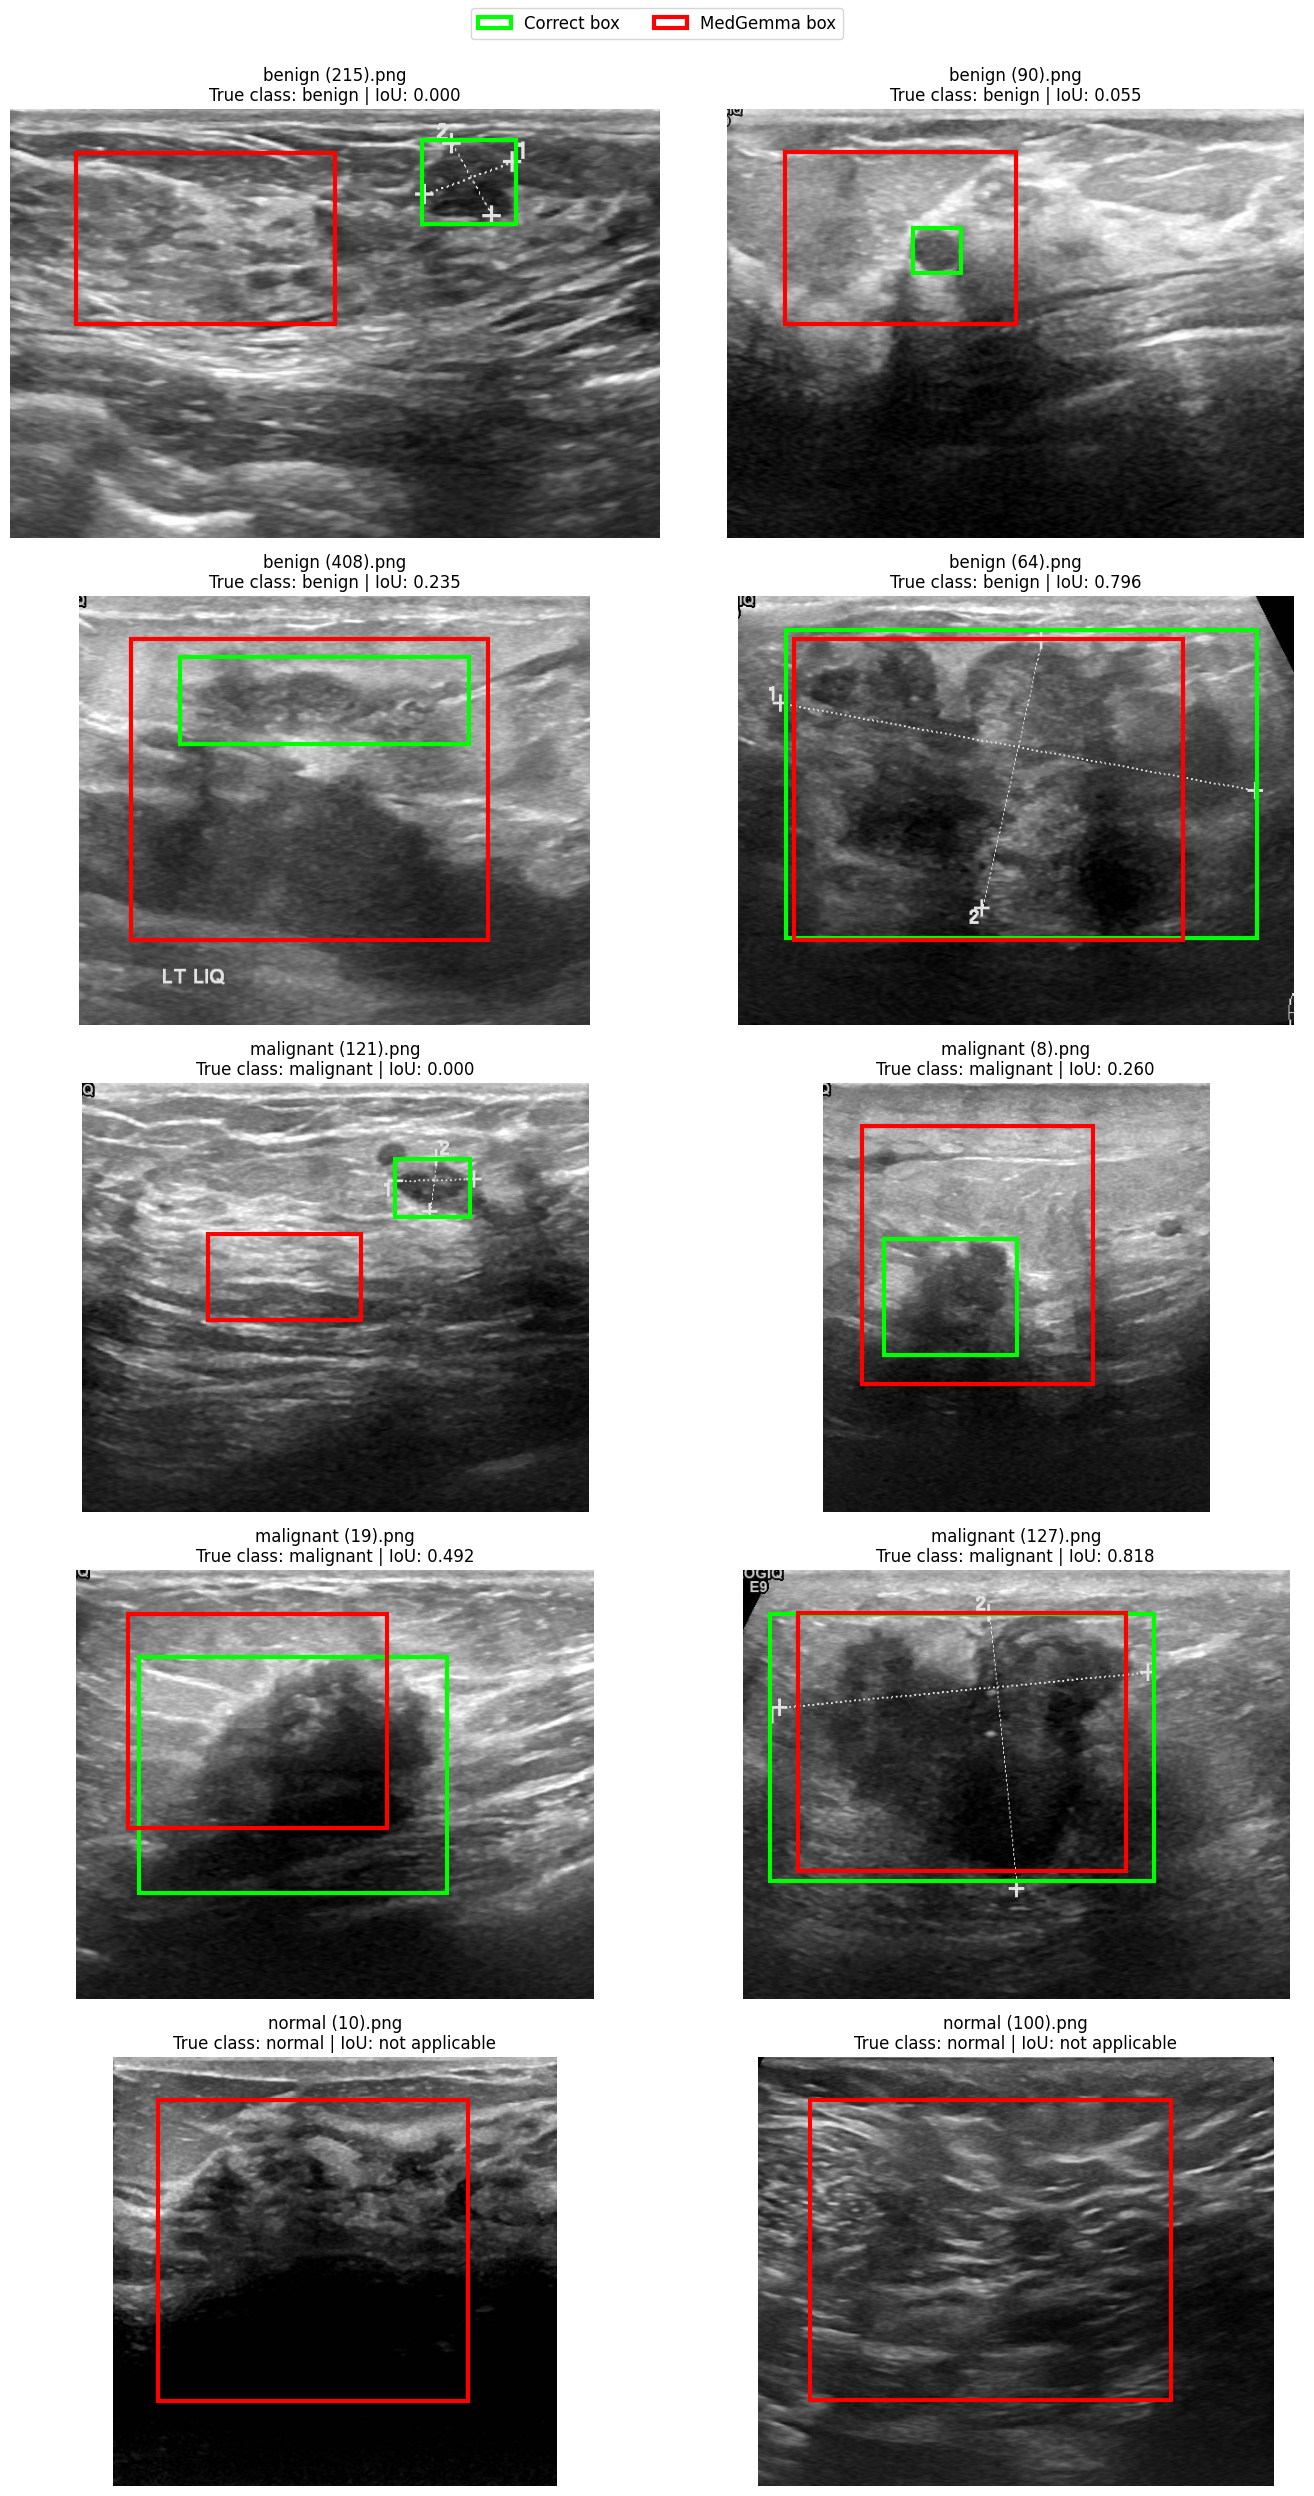

Figure saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_grounding_10_visual_examples.png
Example list saved to: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/busi_grounding/busi_grounding_10_visual_examples.csv
Examples displayed: 10


In [37]:
def select_spread_examples(class_df, number_to_select):
    sorted_df = class_df.sort_values("iou").reset_index(drop=True)

    positions = np.linspace(
        0,
        len(sorted_df) - 1,
        number_to_select
    ).round().astype(int)

    return sorted_df.iloc[positions]


benign_examples = select_spread_examples(
    test_results_df.loc[
        test_results_df["true_label"] == "benign"
    ],
    4
)

malignant_examples = select_spread_examples(
    test_results_df.loc[
        test_results_df["true_label"] == "malignant"
    ],
    4
)

normal_examples = (
    test_results_df.loc[
        test_results_df["true_label"] == "normal"
    ]
    .sort_values("image_id")
    .head(2)
)

selected_examples_df = pd.concat(
    [
        benign_examples,
        malignant_examples,
        normal_examples
    ],
    ignore_index=True
)

selected_examples_df = selected_examples_df.drop(
    columns=["ground_truth_box"],
    errors="ignore"
).merge(
    test_ground_truth_df[
        [
            "image_id",
            "image_path",
            "ground_truth_box"
        ]
    ],
    on="image_id",
    how="left",
    validate="one_to_one"
)


def read_saved_box(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return None

    return ast.literal_eval(value)


fig, axes = plt.subplots(
    5,
    2,
    figsize=(14, 25)
)

axes = axes.flatten()

for ax, (_, row) in zip(
    axes,
    selected_examples_df.iterrows()
):
    image = Image.open(row["image_path"]).convert("RGB")

    correct_box = row["ground_truth_box"]
    predicted_box = read_saved_box(
        row["predicted_pixel_box"]
    )

    ax.imshow(image)

    if correct_box is not None:
        x_min, y_min, x_max, y_max = correct_box

        ax.add_patch(Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            edgecolor="lime",
            facecolor="none",
            linewidth=3
        ))

    if predicted_box is not None:
        x_min, y_min, x_max, y_max = predicted_box

        ax.add_patch(Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            edgecolor="red",
            facecolor="none",
            linewidth=3
        ))

    if row["true_label"] == "normal":
        score_text = "IoU: not applicable"
    else:
        score_text = f"IoU: {row['iou']:.3f}"

    ax.set_title(
        f"{row['image_id']}\n"
        f"True class: {row['true_label']} | {score_text}"
    )

    ax.axis("off")

from matplotlib.patches import Patch

fig.legend(
    handles=[
        Patch(
            edgecolor="lime",
            facecolor="none",
            linewidth=3,
            label="Correct box"
        ),
        Patch(
            edgecolor="red",
            facecolor="none",
            linewidth=3,
            label="MedGemma box"
        )
    ],
    loc="upper center",
    ncol=2,
    fontsize=12
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

VISUAL_EXAMPLES_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_grounding_10_visual_examples.png"
)

SELECTED_EXAMPLES_PATH = (
    GROUNDING_RESULTS_DIR
    / "busi_grounding_10_visual_examples.csv"
)

plt.savefig(
    VISUAL_EXAMPLES_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

selected_examples_df.to_csv(
    SELECTED_EXAMPLES_PATH,
    index=False
)

print("Figure saved to:", VISUAL_EXAMPLES_PATH)
print("Example list saved to:", SELECTED_EXAMPLES_PATH)
print("Examples displayed:", len(selected_examples_df))

Step 29: Verifying the Week 4 files

This confirms that the raw results, IoU tables, ground-truth boxes, and visual examples were all saved successfully.

In [38]:
required_files = {
    "Ground-truth boxes": TEST_GROUND_TRUTH_PATH,
    "Raw MedGemma results": TEST_RESULTS_PATH,
    "Overall IoU summary": FINAL_SUMMARY_PATH,
    "Per-class results": PER_CLASS_RESULTS_PATH,
    "Ten-example figure": VISUAL_EXAMPLES_PATH,
    "Ten-example list": SELECTED_EXAMPLES_PATH
}

verification_records = []

for description, file_path in required_files.items():
    verification_records.append({
        "file": description,
        "exists": file_path.exists(),
        "path": str(file_path)
    })

verification_df = pd.DataFrame(verification_records)

display(verification_df)

print(
    "Raw-result rows:",
    len(pd.read_csv(TEST_RESULTS_PATH))
)

print(
    "Ground-truth rows:",
    len(pd.read_csv(TEST_GROUND_TRUTH_PATH))
)

print(
    "Visual examples:",
    len(pd.read_csv(SELECTED_EXAMPLES_PATH))
)

assert verification_df["exists"].all()
assert len(pd.read_csv(TEST_RESULTS_PATH)) == len(
    pd.read_csv(TEST_GROUND_TRUTH_PATH)
)

print("\nWeek 4 file verification passed.")

,file,exists,path
0,Ground-truth boxes,True,/content/drive/MyDrive/Ultrasound_Project-Siyo...
1,Raw MedGemma results,True,/content/drive/MyDrive/Ultrasound_Project-Siyo...
2,Overall IoU summary,True,/content/drive/MyDrive/Ultrasound_Project-Siyo...
3,Per-class results,True,/content/drive/MyDrive/Ultrasound_Project-Siyo...
4,Ten-example figure,True,/content/drive/MyDrive/Ultrasound_Project-Siyo...
5,Ten-example list,True,/content/drive/MyDrive/Ultrasound_Project-Siyo...


Raw-result rows: 760
Ground-truth rows: 760
Visual examples: 10

Week 4 file verification passed.


Week 4 is complete and verified.

Final BUSI grounding results:

- Test images: 760
- Valid model responses: 100%
- Mean IoU on lesion images: 0.239
- Median IoU: 0.205
- IoU ≥ 0.25: 42.47%
- IoU ≥ 0.50: 13.15%
- Average time per image: 5.91 seconds

Main finding: MedGemma predicted a lesion in every image. It detected lesion presence for all benign and malignant images, but falsely predicted lesions in all 129 normal images. Grounding was better for malignant images than benign images.

All required evidence was saved:

- Mask-to-box conversions
- Raw results for 760 images
- Overall and per-class IoU results
- Ten visual examples
- Verified Week 4 notebook: `04_busi_grounding.ipynb`